# Ranking Spike Sequences by Fitness and Evaluating Cumulative Tip Scores

In this notebook, we explore multiple ranking methods to prioritize spike sequences based on their fitness estimates. These methods include:

- PyR0 fitness scores  
- EVEscape model scores  
- CoVFit model scores

We then evaluate the performance of each ranking by analyzing how well the top-ranked sequences capture future tips cumulatively over various time slices.

This approach helps identify ranking strategies that best forecast viral evolutionary trends and guide variant surveillance.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    with open(file_path, 'rb') as file:
        return pickle.load(file)

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/sukhanna/MPP/"
PARENT_PATH = ROOT_PATH +"ver_2/ver_2A/new_MAT/"
DATA_PATH = PARENT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(PARENT_PATH + "sequence_dict.pkl")

refSeq = getReference(ROOT_PATH + 'cov_reference.fa')

# ver = 'Nov_29_21'
ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

eve_df = pd.read_csv(ROOT_PATH + 'EVEscape/EVEscore_Wuhan_A')

Create Disjoint time interval slices

In [ ]:
# --- Define cutoff date ---
cutoff_date = "2022-07-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Perform slicing ---
# cumulative_slices = slice_by_cumulative_windows(future_df, cumulative_windows)
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Combine slices into one dictionary ---
future_slices = disjoint_slices

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


In [7]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 17477 unique sequences
Computed future sequence DataFrames for 4 windows


# CoVFit Fitness Score Ranking

We will compute the CoVFit ranking using the precomputed per-sequence average fitness scores.

In [8]:
# --- Load CoVFit fitness scores ---
# data_path = f"/data/sukhanna/MPP/ver_2/ver_2A/Contiguous_15D/{cutoff_date}/"
data_path = f"/data/sukhanna/MPP/ver_2/ver_2A/new_MAT/Disjoint_{d}D/{cutoff_date}/" # For experiments only
f_name = "CoVFit_Predictions_fold_3.tsv"
file_path = data_path + f_name

covfit_score_df = pd.read_csv(file_path, sep="\t")

# --- Standardize column names ---
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

# --- Merge fitness scores with current sequence DataFrame ---
current_seq_df = current_seq_df.merge(
    covfit_score_df[["Sequence_ID", "fitness_mean"]],
    on="Sequence_ID",
    how="left"
)

# --- Summary output ---
print(f"Loaded {len(covfit_score_df)} CoVFit score entries")
print(f"Merged fitness scores into current sequence DataFrame with {len(current_seq_df)} sequences")

Loaded 17477 CoVFit score entries
Merged fitness scores into current sequence DataFrame with 17477 sequences


# PyR0 and EVEscape Ranking

Rank sequences using:
- **PyR₀ score**: product of R/Rₐ values across all spike mutations.  
- **EVEscape score**: sum of EVEsape scores across all soike mutations using Wuhan_A scoring.  


In [9]:
# --- Build mutation-to-score dictionaries ---
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

mutation_score_dict_eve = (
    eve_df.set_index("mutations")["EVEscape"].to_dict()
)

# --- Summary output ---
print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")
print(f"Loaded {len(mutation_score_dict_eve)} EVEscape mutation scores")

Loaded 3211 PyR₀ mutation scores
Loaded 24187 EVEscape mutation scores


In [10]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

# --- Compute EVEscape fitness scores ---
current_seq_df = add_fitness_scores_eve(current_seq_df, mutation_score_dict_eve)

# --- Summary output ---
print(f"Computed mutations and fitness scores for {len(current_seq_df)} sequences")

Computed mutations and fitness scores for 17477 sequences


In [11]:
current_seq_df.head()

,Sequence_ID,Tip_Count,fitness_mean,Mutations,Fitness_Score_pyro,Fitness_Score_eve
0,S_538,166487,0.531965,"(S:T19I, S:V213G, S:G339D, S:S371F, S:S373P, S...",4.192588,97.858691
1,S_2547,93202,0.470395,"(S:T19I, S:V213G, S:G339D, S:S371F, S:S373P, S...",3.904831,100.816533
2,S_373,74466,0.442728,"(S:T19I, S:V213G, S:G339D, S:S371F, S:S373P, S...",3.867781,94.472081
3,S_12420,23015,0.521130,"(S:V3G, S:T19I, S:V213G, S:G339D, S:S371F, S:S...",4.196278,100.179143
4,S_186313,13435,0.530407,"(S:T19I, S:T76I, S:V213G, S:G339D, S:S371F, S:...",4.202692,101.650494


In [12]:
# --- Compute cumulative tip percentages for all ranking methods ---
rank_results = compute_cumulative_tip_percentages_fast(
    current_seq_df,
    future_seq_dfs,
    max_rank=None
)

# --- Summary output ---
print(f"Computed cumulative tip percentages for {len(rank_results)} future time windows")

Computed cumulative tip percentages for 4 future time windows


In [13]:
# --- Compute normalized AUC for each ranking method ---
auc_scores = compute_auc_for_rank_results(rank_results)

In [14]:
auc_scores

{'3M_1': {'pyro': 0.7937768051080041,
  'eve': 0.3443419653206015,
  'covfit': 0.7878050548481234,
  'tip_count': 0.9191399598900316},
 '3M_2': {'pyro': 0.7036678454396553,
  'eve': 0.5346117935737676,
  'covfit': 0.7299136497073734,
  'tip_count': 0.7275235253248257},
 '3M_3': {'pyro': 0.5710923282058311,
  'eve': 0.5462090827149855,
  'covfit': 0.5837541378176647,
  'tip_count': 0.5542643353438572},
 '3M_4': {'pyro': 0.3045797228837177,
  'eve': 0.30206980578609127,
  'covfit': 0.30645629369062183,
  'tip_count': 0.2951035720423084}}

In [15]:
# --- Compute normalized AUC ceiling per slice based on achievable tips ---
auc_ceil_dict = compute_auc_ceil_fraction(current_seq_df, future_seq_dfs)

# --- Display per-slice AUC ceilings ---
for time_slice, auc_ceil in auc_ceil_dict.items():
    print(f"Time slice: {time_slice} | Normalized AUC ceiling: {auc_ceil:.3f}")

Time slice: 3M_1 | Normalized AUC ceiling: 0.939
Time slice: 3M_2 | Normalized AUC ceiling: 0.770
Time slice: 3M_3 | Normalized AUC ceiling: 0.591
Time slice: 3M_4 | Normalized AUC ceiling: 0.308


# Plotting Results

The following plots visualize the performance of different ranking methods in capturing future tips.  
Each main panel shows the cumulative fraction of future tips captured by the top-ranked sequences over a given time interval.  
Inset panels display the corresponding normalized AUC scores for each method, with a reference line indicating the achievable ceiling.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

sns.set_style("whitegrid")
sns.set_context("talk")

def plot_2x2_cumulative_auto(rank_results, auc_scores, auc_ceil, cutoff_date):
    slice_keys = list(rank_results.keys())[:4]

    legend_map = {
        "pyro": "PyR0 Fitness Score",
        "eve": "EVEscape Fitness Score",
        "covfit": "CoVFit Fitness Score",
        "tip_count": "Prevalence Score"
    }
    panel_head = {
        '3M_1' : '0 - 3 months',
        '3M_2' : '3 - 6 months',
        '3M_3' : '6 - 9 months',
        '3M_4' : '9 - 12 months'
    }

    base_palette = sns.color_palette("colorblind", n_colors=4)
    color_map = {
        "pyro": base_palette[0],
        "eve": base_palette[1],
        "covfit": base_palette[2],
        "tip_count": base_palette[3]
    }

    fig, axes = plt.subplots(2, 2, figsize=(24, 18), sharex=True, sharey=True)
    axes = axes.flatten()
    fig.suptitle(f'% Future Tips Captured by Rank: {cutoff_date}', fontsize=24, y = 0.95)

    legend_handles = []
    legend_labels = []

    for i, key in enumerate(slice_keys):
        df = rank_results[key]
        ax = axes[i]

        tip_cols = [col for col in df.columns if col.startswith('%_tips_')]
        methods = [col.replace('%_tips_', '') for col in tip_cols]

        # Main lineplots
        for method in methods:
            label_name = legend_map.get(method, method)
            sns.lineplot(
                data=df,
                x="Rank",
                y=f"%_tips_{method}",
                ax=ax,
                linewidth=2.5,
                color=color_map[method],
                legend=False
            )
            if label_name not in legend_labels:
                legend_handles.append(ax.lines[-1])
                legend_labels.append(label_name)

        # X-axis ticks
        max_rank = int(df['Rank'].max())
        tick_base = 10 if max_rank <= 200 else 100 if max_rank <= 2000 else 1000
        tick_vals = list(range(tick_base, max_rank + 1, tick_base))
        if 10 not in tick_vals:
            tick_vals.insert(0, 10)
        if 500 not in tick_vals and 500 <= max_rank:
            tick_vals.append(500)
        tick_vals = sorted(set(tick_vals))
        tick_labels = [f'{x//1000}K' if x >= 1000 else str(x) for x in tick_vals]
        ax.set_xticks(tick_vals)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=16)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_title(f'% Future Tips Captured in {panel_head[key]} interval', fontsize=20)
        ax.set_xlabel('Top Rank', fontsize=18)
        ax.set_ylabel('% Normalized Tip Score', fontsize=18)

        # --- Inset AUC bar plot, bottom-right, no x-ticks ---
        if auc_scores is not None and key in auc_scores:
            inset_ax = inset_axes(ax, width="25%", height="25%", loc='lower right', borderpad=1)
            auc_values = [auc_scores[key].get(m, 0) for m in methods]
            inset_ax.bar(range(len(methods)), auc_values, color=[color_map[m] for m in methods])
            inset_ax.set_title("AUC", fontsize=18)
            inset_ax.set_xticks([])  # remove x-ticks
            inset_ax.set_xlabel("")
            inset_ax.tick_params(axis='y', labelsize=14)
            inset_ax.set_ylim(0, 1)  # y-axis range fixed

            # --- Modification 1: remove grid lines ---
            inset_ax.grid(False)

            # --- Modification 2: add black line at ceiling value ---
            ceil_value = auc_ceil.get(key, 1.0)  # make sure auc_ceil_dict is available
            inset_ax.axhline(y=ceil_value, color='black', linestyle='--', linewidth=2)

    # Shared legend outside
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='center left',
        bbox_to_anchor=(0.9, 0.5),
        fontsize=16,
        title="Ranking Methods",
        title_fontsize=18
    )

    # plt.tight_layout(rect=[0, 0, 0.85, 0.95])
    plt.savefig(f"/data/sukhanna/MPP/ver_2/ver_2A/Final_Images/{cutoff_date}/compartive_rank_trend.svg", format="svg")
    plt.show()

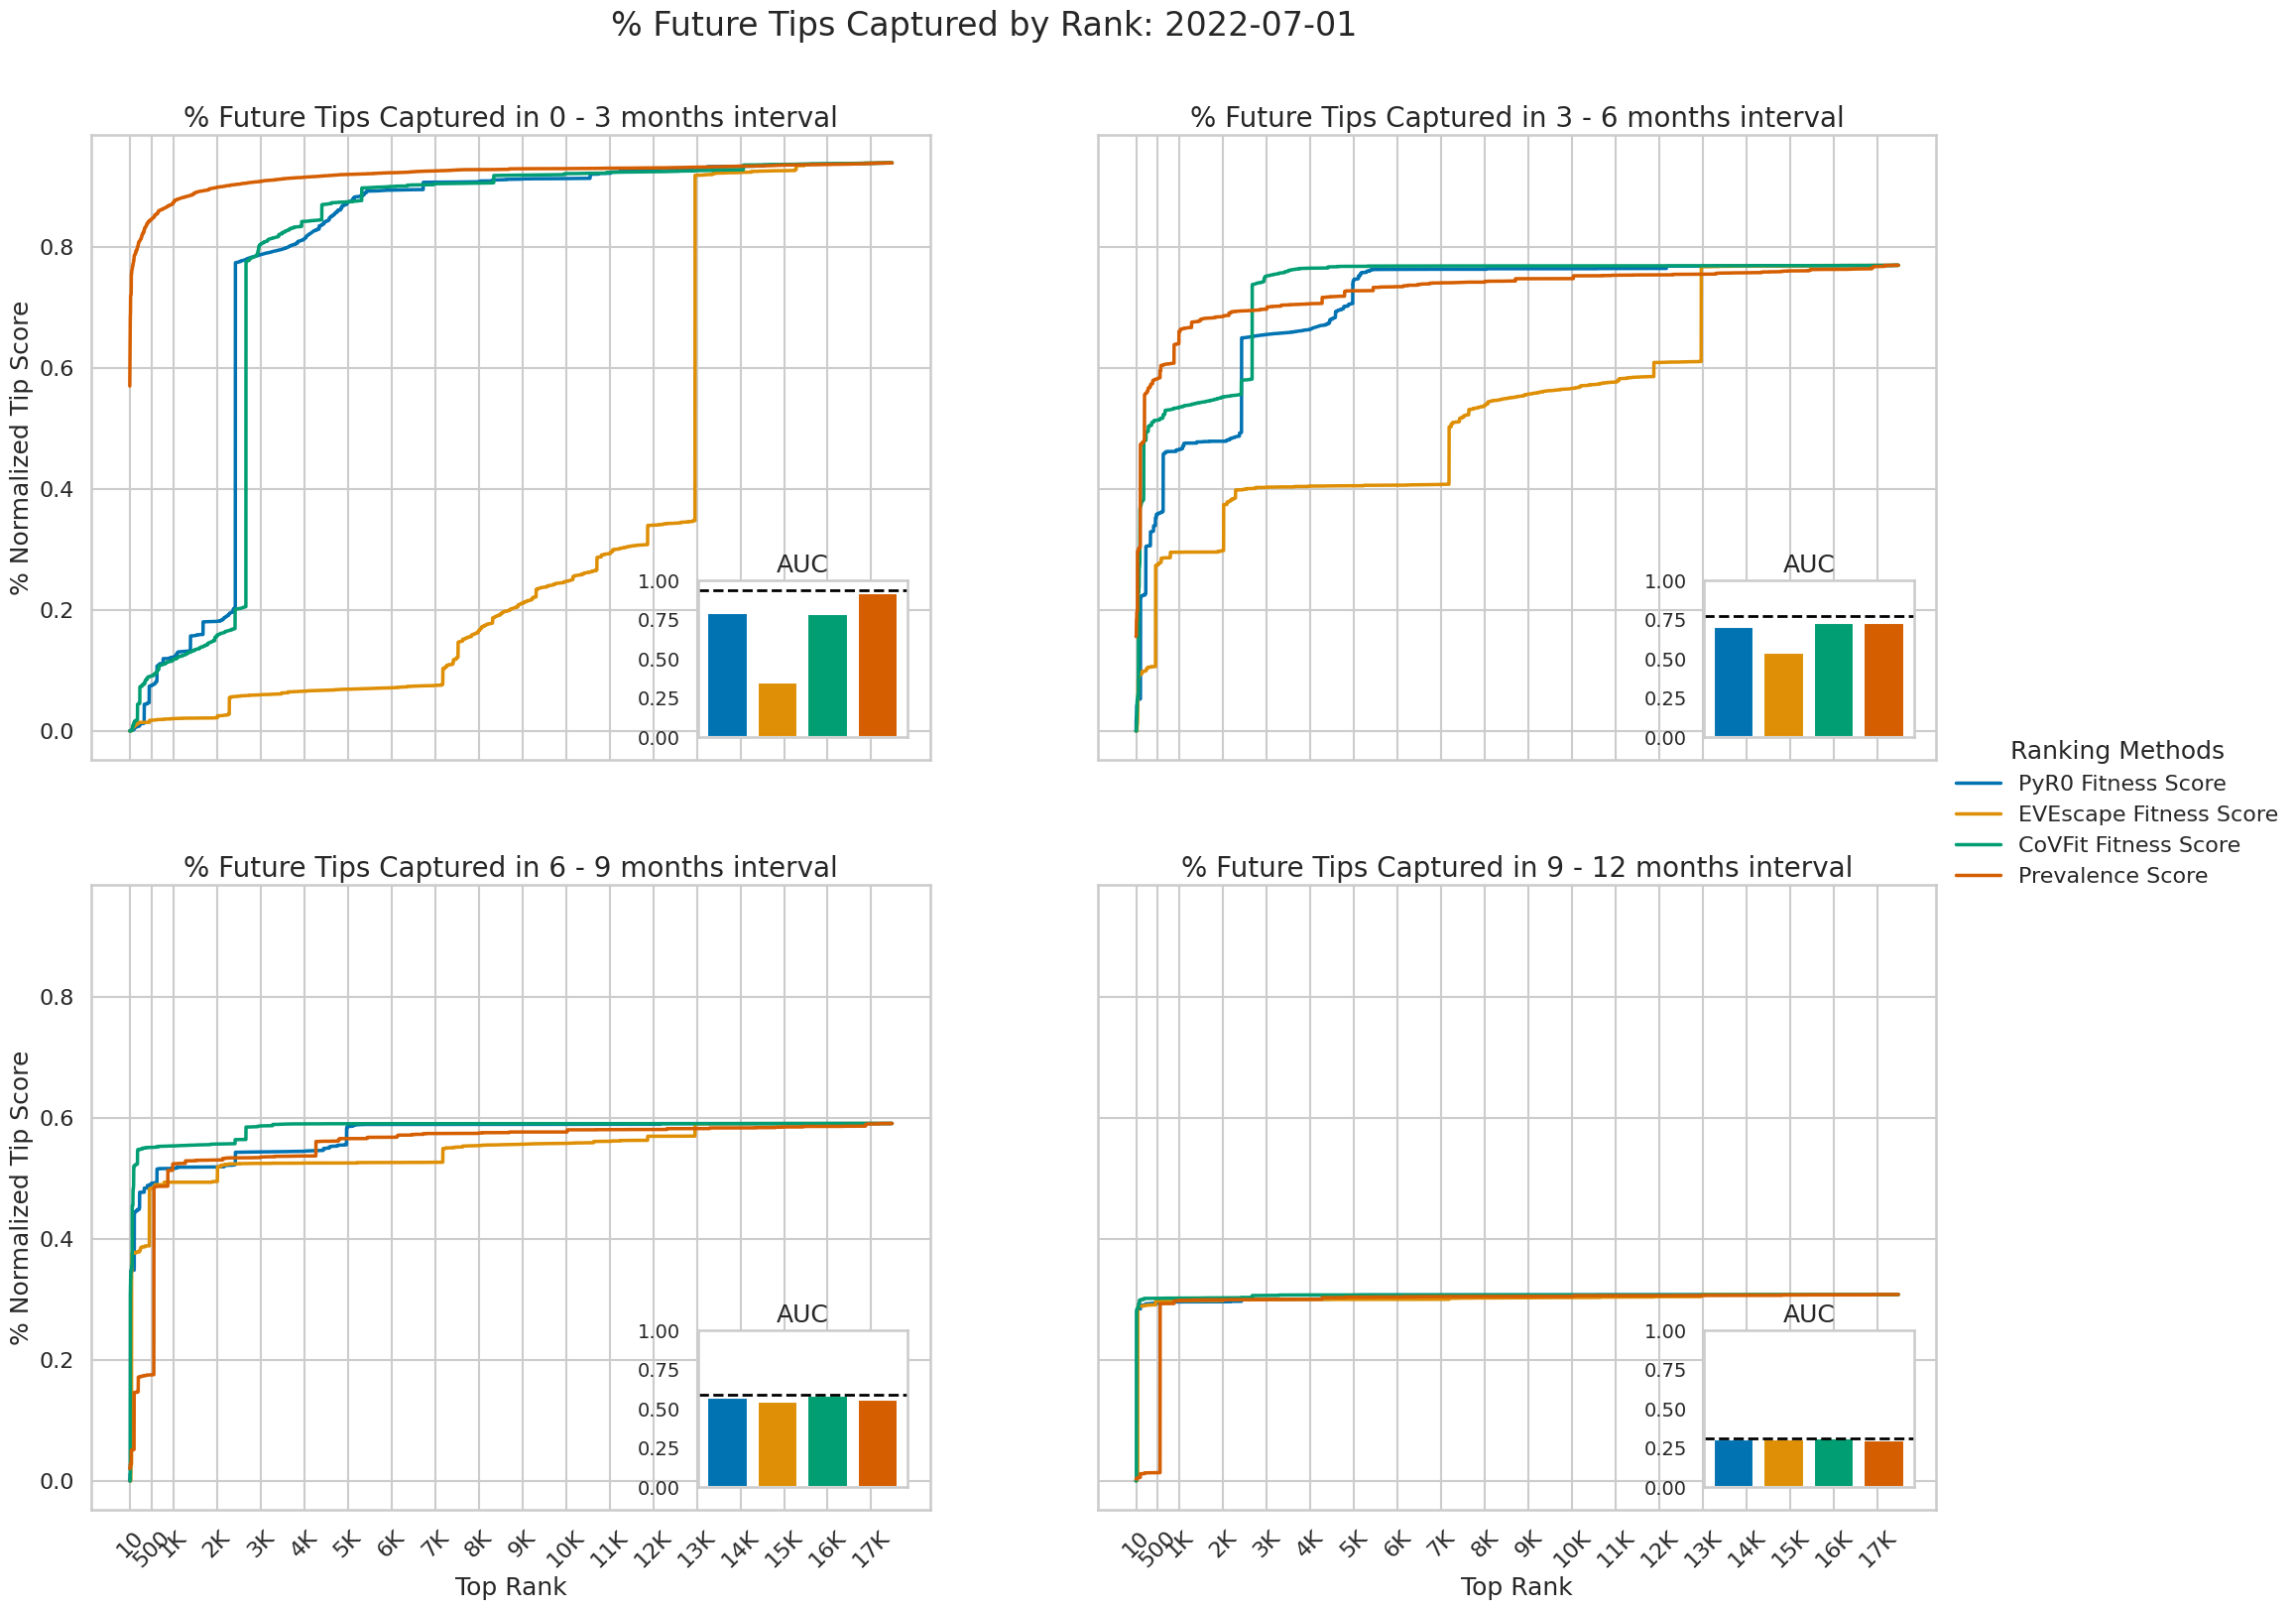

In [17]:
plot_2x2_cumulative_auto(rank_results=rank_results,
                         auc_scores=auc_scores,
                         auc_ceil=auc_ceil_dict,
                         cutoff_date=cutoff_date)

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.lines import Line2D

sns.set_style("whitegrid")
sns.set_context("talk")

def plot_1x4_cumulative_auto(rank_results, auc_scores, auc_ceil, cutoff_date):
    slice_keys = list(rank_results.keys())[:4]

    legend_map = {
        "pyro": "PyR0",
        "eve": "EVEscape",
        "covfit": "CoVFit",
        "tip_count": "Prevalence"
    }
    panel_head = {
        '3M_1' : '0 - 3 months',
        '3M_2' : '3 - 6 months',
        '3M_3' : '6 - 9 months',
        '3M_4' : '9 - 12 months'
    }

    base_palette = sns.color_palette("colorblind", n_colors=4)
    color_map = {
        "pyro": base_palette[0],
        "eve": base_palette[1],
        "covfit": base_palette[2],
        "tip_count": base_palette[3]
    }

    # --- 1x4 grid, wide figure ---
    fig, axes = plt.subplots(1, 4, figsize=(28, 10), sharey=True)

    legend_handles = []
    legend_labels = []

    for i, key in enumerate(slice_keys):
        df = rank_results[key]
        ax = axes[i]

        tip_cols = [col for col in df.columns if col.startswith('%_tips_')]
        methods = [col.replace('%_tips_', '') for col in tip_cols]

        # --- Main lineplots ---
        for method in methods:
            label_name = legend_map.get(method, method)
            sns.lineplot(
                data=df,
                x="Rank",
                y=f"%_tips_{method}",
                ax=ax,
                linewidth=2.5,
                color=color_map[method],
                legend=False
            )
            if label_name not in legend_labels:
                legend_handles.append(ax.lines[-1])
                legend_labels.append(label_name)

        # --- X-axis ticks ---
        max_rank = int(df['Rank'].max())
        tick_base = 10 if max_rank <= 200 else 100 if max_rank <= 2000 else 1000
        tick_vals = list(range(tick_base, max_rank + 1, tick_base))
        # if 10 not in tick_vals:
        #     tick_vals.insert(0, 10)
        if 100 not in tick_vals and 100 <= max_rank:
            tick_vals.append(100)
        tick_vals = sorted(set(tick_vals))
        tick_labels = [f'{x//1000}K' if x >= 1000 else str(x) for x in tick_vals]
        ax.set_xticks(tick_vals)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=14)
        ax.tick_params(axis='y', labelsize=14)

        # --- Labels and title ---
        ax.set_title(f'% Future Tips in {panel_head[key]}', fontsize=20)
        ax.set_xlabel('Top Rank', fontsize=18)
        if i == 0:
            ax.set_ylabel('% Normalized Tip Score', fontsize=18)
        else:
            ax.set_ylabel("")

        # --- Inset AUC bar plot ---
        if auc_scores is not None and key in auc_scores:
            inset_ax = inset_axes(ax, width="30%", height="30%", loc='lower right', borderpad=0.3)
            auc_values = [auc_scores[key].get(m, 0) for m in methods]
            inset_ax.bar(range(len(methods)), auc_values, color=[color_map[m] for m in methods])
            inset_ax.set_title("AUC", fontsize=14)
            inset_ax.set_xticks([])
            inset_ax.set_xlabel("")
            inset_ax.tick_params(axis='y', labelsize=14)
            inset_ax.set_ylim(0, 1)

            inset_ax.grid(False)
            ceil_value = auc_ceil.get(key, 1.0)
            inset_ax.axhline(y=ceil_value, color='black', linestyle='--', linewidth=2)

    

    # --- Dummy Handle for Ceiling ---
    upper_bound_handle = Line2D(
    [0], [0],
    color='black',
    linestyle='--',
    linewidth=2,
    label='Data Upper Bound'
    )

    # Add it to the legend
    insert_index = 0
    legend_handles.insert(insert_index, upper_bound_handle)
    legend_labels.insert(insert_index, 'Data Upper Bound')

    # --- Shared legend outside bottom ---
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='lower center',
        ncol=5,
        fontsize=16,
        title="Ranking Methods",
        title_fontsize=18,
        bbox_to_anchor=(0.5, -0.1)
    )

    # plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.savefig(f"/data/sukhanna/MPP/ver_2/ver_2A/Final_Images/{cutoff_date}/comparative_rank_trend_1x4.svg", format="svg", bbox_inches='tight')
    plt.show()


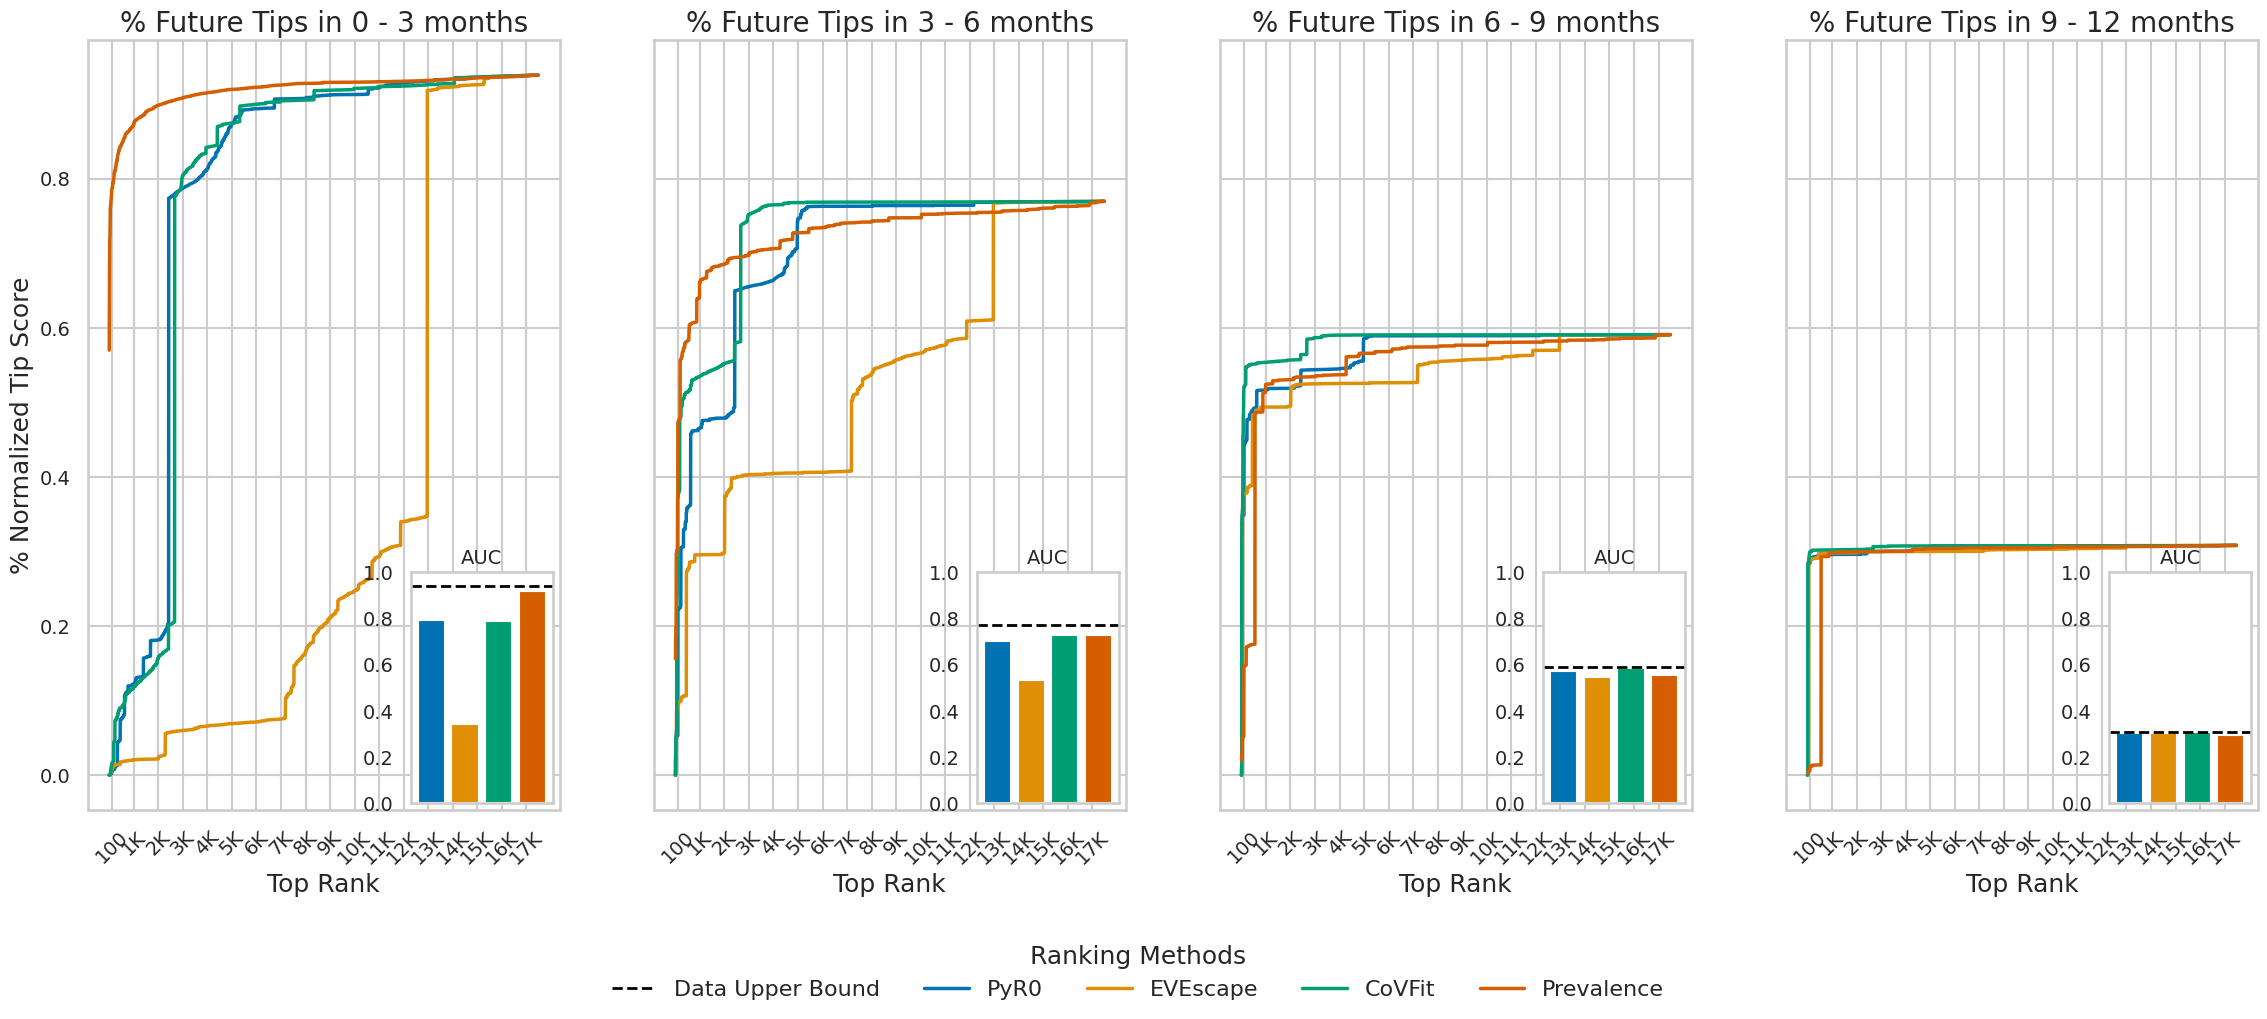

In [59]:
plot_1x4_cumulative_auto(
    rank_results=rank_results,
    auc_scores=auc_scores,
    auc_ceil=auc_ceil_dict,
    cutoff_date=cutoff_date
)